# AgroPest-12 Part B: SimCLR Pretraining for YOLOv12m

**Model:** YOLOv12m backbone, strict label-free SimCLR pretraining  
**Dataset:** AgroPest-12-PartB-Safe SSL pool (9,180 images)  
**Platform:** Kaggle T4 x2  

This notebook pretrains a randomly initialized YOLOv12m backbone with SimCLR. It reads only `ssl_pool/images`; labels, validation images, and test images are never accessed.

## Method and Protocol

SimCLR creates two independently augmented views of each image. The shared YOLOv12m backbone and an MLP projection head produce normalized embeddings. NT-Xent pulls the two views of the same image together while treating other images in the local batch as negatives. The projection head is discarded after pretraining; only the backbone transfers to detection.

The Part B partition policy forbids reading labels, validation images, or test images in this notebook. Diagnostics therefore use a fixed image-only sample from the SSL pool and do not make label-based claims.

In [1]:
# Install the current course SSL library and visualization dependency.
import subprocess, sys

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "ultralytics>=8.4.96", "scikit-learn", "seaborn"])
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "--no-deps", "git+https://github.com/rifat963/ssl-detection-lab.git@main"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.1/46.1 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 57.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 112.6 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sklearn-compat 0.1.5 requires scikit-learn<1.9,>=1.2, but you have scikit-learn 1.9.0 which is incompatible.


0

In [2]:
# ============================================================
# CONFIG -- every value is fixed and viva-explainable
# ============================================================
from pathlib import Path

PARTB_ROOT = Path("/kaggle/input/datasets/sadikshahriar/agropest-12-partb-safe/AgroPest-12-PartB-Safe")
SSL_IMAGES = PARTB_ROOT / "ssl_pool" / "images"
OUTPUT_DIR = Path("/kaggle/working/partB_01a_simclr_yolo12m")

SEED = 445                 # Shared Part B seed and fixed diagnostic sample.
YOLO_MODEL = "yolo12m.yaml" # Random architecture: no COCO-supervised initialization.
EPOCHS = 30                # Assignment B standard SSL pretraining budget.
IMAGE_SIZE = 224           # 88.9% of AgroPest boxes are large; preserves morphology while fitting a T4 contrastive batch.
PER_GPU_BATCH = 128        # Measured maximum fitting in 12 GB/T4: 256 views/rank and 254 negatives per anchor.
WORKERS = 2                # Matches the Part A two-workers-per-GPU data-loading budget.
LEARNING_RATE = 3e-4       # Conservative AdamW rate validated by the 128/GPU one-epoch smoke run.
MIN_LEARNING_RATE = 3e-6   # 100x lower cosine-decay floor for this 30-epoch SSL run.
WEIGHT_DECAY = 1e-4        # SSL regularization for the random encoder and projector.
WARMUP_EPOCHS = 1          # Stabilizes random initialization without reducing the short SSL budget materially.
PROJECTION_DIM = 128       # Compact contrastive bottleneck; discarded before detector transfer.
HIDDEN_DIM = 512           # Matches the YOLOv12m pooled-feature scale without over-sizing the pretext-only MLP.
TEMPERATURE = 0.20         # Stable NT-Xent temperature with the measured 254 local negatives per anchor.
DIAGNOSTIC_IMAGES = 500    # Fixed image-only SSL-pool sample for t-SNE/retrieval.
RETRIEVAL_QUERIES = 4      # Four random panels, matching the earlier SimCLR sanity-check style.
RETRIEVAL_NEIGHBORS = 5    # Assignment B requires query plus top-five cosine neighbours.

CLASS_NAMES = ["Ants", "Bees", "Beetles", "Caterpillars", "Earthworms", "Earwigs", "Grasshoppers", "Moths", "Slugs", "Snails", "Wasps", "Weevils"]
print(f"CONFIG loaded | SimCLR | {YOLO_MODEL} | {EPOCHS} epochs | {PER_GPU_BATCH} images/GPU | {IMAGE_SIZE}px")

CONFIG loaded | SimCLR | yolo12m.yaml | 30 epochs | 128 images/GPU | 224px


## Dataset-Specific CONFIG Rationale

This is not a copied football configuration. AgroPest images are native 640×640 and EDA found 88.9% large boxes, so 224px retains the dominant pest morphology for global SSL features while allowing a local SimCLR batch of 32 on each 16 GB T4. The downstream detector still fine-tunes at 640px for localization.

The current library keeps negatives local to each DDP rank. A one-epoch Kaggle smoke run measured that 128 source images/GPU uses about 12 GB of each 15 GB T4 without OOM. Each rank therefore has 256 view representations: one positive and 254 negatives per NT-Xent anchor. This is more useful to SimCLR than gradient accumulation, which does not increase simultaneous negatives. The built-in SimCLR transform uses moderate colour jitter (0.35), low hue jitter (0.06), and grayscale probability 0.10, preserving more colour information than canonical aggressive SimCLR while still learning outdoor lighting invariance.

The encoder begins from `yolo12m.yaml`, not COCO weights, so the learned features are attributable to the 9,180 label-free AgroPest images. AdamW with `3e-4`, `1e-4` weight decay, one warmup epoch, cosine decay to `3e-6`, AMP, and gradient clipping are the current course-library stability controls for a 30-epoch random-initialization run.

In [3]:
# ============================================================
# Environment and strict SSL-pool-only checks
# ============================================================
import json, random
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from PIL import Image
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset
from torchvision.transforms import v2
from tqdm.auto import tqdm
from ultralytics import YOLO

import ssldet
from ssldet import PretrainConfig, assert_supported_runtime, available_ssl_modules, launch_distributed_pretrain, transfer_ssl_backbone_to_yolo
from ssldet.backbones import YOLOBackboneEncoder
from ssldet.data import IMAGENET_MEAN, IMAGENET_STD, UnlabeledImageDataset, build_transform

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.set_float32_matmul_precision("high")
sns.set_theme(style="whitegrid")

assert SSL_IMAGES.is_dir(), f"Attach AgroPest-12-PartB-Safe. Missing: {SSL_IMAGES}"
assert not any(SSL_IMAGES.parent.rglob("*.txt")), "SSL pool must not contain label files."
runtime = assert_supported_runtime(require_cuda=True, minimum_gpus=2)
assert "simclr" in available_ssl_modules()

IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png"}
ssl_paths = sorted(path for path in SSL_IMAGES.iterdir() if path.suffix.lower() in IMAGE_SUFFIXES)
assert len(ssl_paths) == 9180, f"Expected 9,180 SSL images, found {len(ssl_paths)}"

pd.Series({
    "ssl-detection-lab": ssldet.__version__, "PyTorch": torch.__version__,
    "Ultralytics": runtime["packages"]["ultralytics"]["installed"],
    "GPU count": runtime["cuda"]["device_count"],
    "GPUs": ", ".join(device["name"] for device in runtime["cuda"]["devices"]),
    "SSL images": len(ssl_paths), "label files visible": 0,
})

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


ssl-detection-lab                   0.8.0
PyTorch                      2.10.0+cu128
Ultralytics                       8.4.105
GPU count                               2
GPUs                   Tesla T4, Tesla T4
SSL images                           9180
label files visible                     0
dtype: object

## Augmentation Preview

SimCLR uses random resized crops, horizontal flips, colour jitter, occasional grayscale conversion, and Gaussian blur. The two views should retain enough pest and scene content to be recognized as the same source image. Aggressive crops can remove a pest completely, so this preview is checked before training.

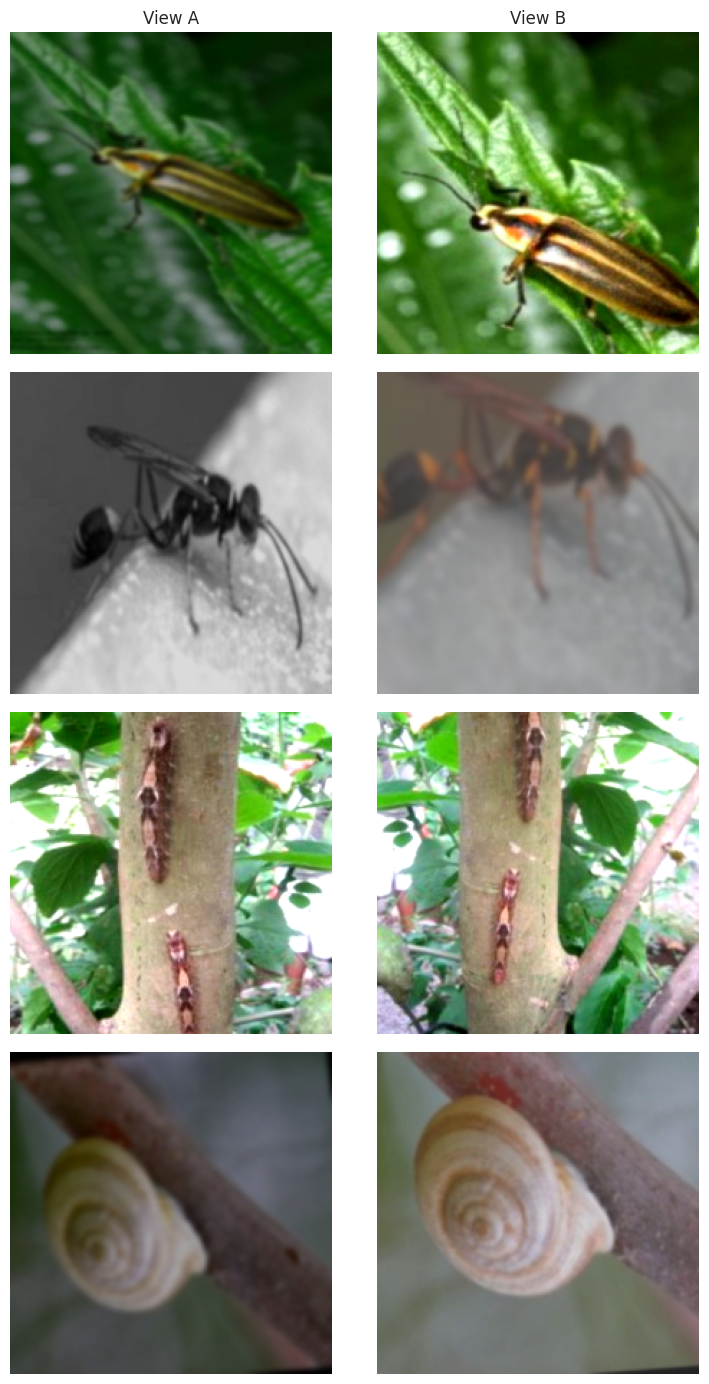

model initialization                  random yolo12m.yaml (strict label-free SSL)
source images per DDP step                                                    256
views per DDP step                                                            512
local NT-Xent representations/rank                                            256
temperature                                                                   0.2
AMP                                                                          True
dtype: object

In [4]:
config = PretrainConfig(
    method="simclr", image_roots=[str(SSL_IMAGES)], output_dir=str(OUTPUT_DIR), yolo_model=YOLO_MODEL,
    epochs=EPOCHS, batch_size=PER_GPU_BATCH, image_size=IMAGE_SIZE, workers=WORKERS,
    seed=SEED, learning_rate=LEARNING_RATE, min_learning_rate=MIN_LEARNING_RATE,
    weight_decay=WEIGHT_DECAY, warmup_epochs=WARMUP_EPOCHS, grad_accum_steps=1,
    gradient_clip=5.0, amp=True, projection_dim=PROJECTION_DIM, hidden_dim=HIDDEN_DIM,
    temperature=TEMPERATURE, save_every=1,
).validate()

preview_dataset = UnlabeledImageDataset(ssl_paths, build_transform(config))
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
def denormalize(tensor):
    return (tensor.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0)

fig, axes = plt.subplots(4, 2, figsize=(8, 14))
for row, index in enumerate(random.Random(233).sample(range(len(preview_dataset)), 4)):
    view_a, view_b = preview_dataset[index]
    axes[row, 0].imshow(denormalize(view_a)); axes[row, 1].imshow(denormalize(view_b))
    axes[row, 0].set_ylabel(ssl_paths[index].name[:28], fontsize=8)
    for axis in axes[row]: axis.axis("off")
axes[0, 0].set_title("View A"); axes[0, 1].set_title("View B")
plt.tight_layout(); plt.show()

pd.Series({
    "model initialization": "random yolo12m.yaml (strict label-free SSL)",
    "source images per DDP step": PER_GPU_BATCH * runtime["cuda"]["device_count"],
    "views per DDP step": 2 * PER_GPU_BATCH * runtime["cuda"]["device_count"],
    "local NT-Xent representations/rank": 2 * PER_GPU_BATCH,
    "temperature": TEMPERATURE, "AMP": config.amp,
})

## Distributed SimCLR Pretraining

The library launches one process per T4 GPU, saves a complete resumable SSL checkpoint each epoch, and records the configuration and initialization in a run manifest. The loss is an SSL optimization signal, not detection mAP.

In [5]:
training_result = launch_distributed_pretrain(
    config, num_processes=runtime["cuda"]["device_count"],
    config_path=OUTPUT_DIR / "simclr_config.yaml", check=True,
)
print(pd.Series({"completed": training_result.succeeded, "seconds": round(training_result.seconds, 1), "output": str(training_result.output_dir)}))

SIMCLR 01/30:   0%|          | 0/35 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/ssldet/trainer.py:203: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
/usr/local/lib/python3.12/dist-packages/ssldet/trainer.py:203: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()
SIMC

Epoch 01 | loss=4.96176 | time=111.8s


SIMCLR 02/30: 100%|██████████| 35/35 [01:36<00:00,  2.75s/it, ema=0.99604, loss=4.1097, lr=2.99e-04]


Epoch 02 | loss=4.10258 | time=96.4s


SIMCLR 03/30: 100%|██████████| 35/35 [01:38<00:00,  2.80s/it, ema=0.99610, loss=3.5154, lr=2.97e-04]


...

Epoch 29 | loss=1.74228 | time=93.6s


SIMCLR 30/30: 100%|██████████| 35/35 [01:31<00:00,  2.60s/it, ema=1.00000, loss=1.7339, lr=3.00e-06]


Epoch 30 | loss=1.73647 | time=91.0s


/usr/local/lib/python3.12/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)


{
  "output_dir": "/kaggle/working/partB_01a_simclr_yolo12m",
  "yolo_checkpoint": "/kaggle/working/partB_01a_simclr_yolo12m/simclr_pretrained_yolo12m.pt",
  "ssl_checkpoint": "/kaggle/working/partB_01a_simclr_yolo12m/last_ssl.pt",
  "history_csv": "/kaggle/working/partB_01a_simclr_yolo12m/history.csv",
  "manifest_json": "/kaggle/working/partB_01a_simclr_yolo12m/run_manifest.json"
}
{
  "output_dir": "/kaggle/working/partB_01a_simclr_yolo12m",
  "yolo_checkpoint": "/kaggle/working/partB_01a_simclr_yolo12m/simclr_pretrained_yolo12m.pt",
  "ssl_checkpoint": "/kaggle/working/partB_01a_simclr_yolo12m/last_ssl.pt",
  "history_csv": "/kaggle/working/partB_01a_simclr_yolo12m/history.csv",
  "manifest_json": "/kaggle/working/partB_01a_simclr_yolo12m/run_manifest.json"
}
completed                                        True
seconds                                        2946.9
output       /kaggle/working/partB_01a_simclr_yolo12m
dtype: object


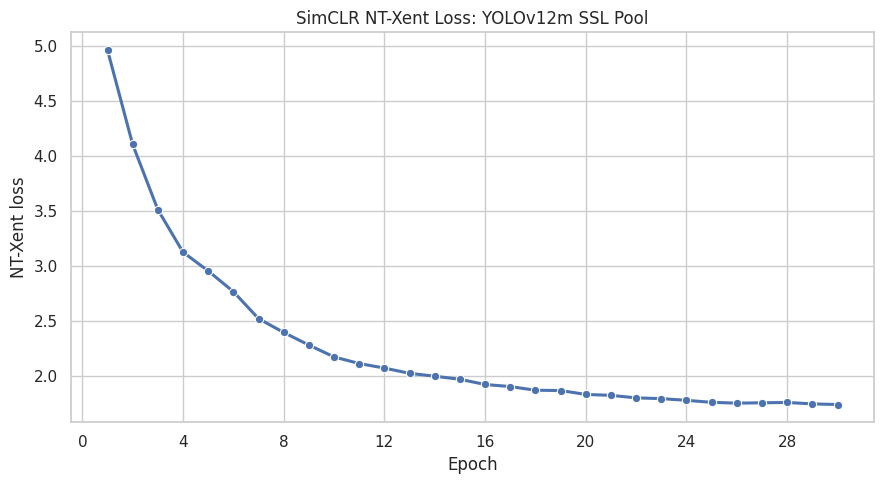

best SSL loss                                                              1.736473
best SSL checkpoint               /kaggle/working/partB_01a_simclr_yolo12m/best_...
latest resumable checkpoint       /kaggle/working/partB_01a_simclr_yolo12m/last_...
detector-compatible checkpoint    /kaggle/working/partB_01a_simclr_yolo12m/simcl...
backbone key coverage                                                        100.0%
transfer report                   /kaggle/working/partB_01a_simclr_yolo12m/simcl...
dtype: object

In [6]:
# ============================================================
# Loss curve and checkpoint handoff
# ============================================================
history = pd.read_csv(OUTPUT_DIR / "history.csv")
manifest = json.loads((OUTPUT_DIR / "run_manifest.json").read_text(encoding="utf-8"))
LAST_SSL_CHECKPOINT = Path(manifest["outputs"]["ssl_checkpoint"])
SSL_CHECKPOINT = OUTPUT_DIR / "best_ssl.pt"
assert SSL_CHECKPOINT.is_file(), f"Missing lowest-loss checkpoint: {SSL_CHECKPOINT}"

fig, axis = plt.subplots(figsize=(9, 5))
sns.lineplot(data=history, x="epoch", y="loss", marker="o", linewidth=2.2, ax=axis)
axis.set(title="SimCLR NT-Xent Loss: YOLOv12m SSL Pool", xlabel="Epoch", ylabel="NT-Xent loss")
axis.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "simclr_loss_curve.png", dpi=160); plt.show()

TRANSFERRED_YOLO = OUTPUT_DIR / "simclr_best_backbone_yolo12m.pt"
transfer = transfer_ssl_backbone_to_yolo(
    SSL_CHECKPOINT, TRANSFERRED_YOLO, yolo_model=YOLO_MODEL, minimum_coverage=0.95,
)
pd.Series({
    "best SSL loss": manifest["best_loss"], "best SSL checkpoint": str(SSL_CHECKPOINT),
    "latest resumable checkpoint": str(LAST_SSL_CHECKPOINT),
    "detector-compatible checkpoint": str(TRANSFERRED_YOLO),
    "backbone key coverage": f"{transfer.coverage:.1%}", "transfer report": str(transfer.report_json),
})

## Representation Diagnostics And Retrieval Sanity Check

These diagnostics use a fixed, image-only sample from `ssl_pool/images`, not validation or test data. t-SNE preserves local neighborhoods only and is exploratory. The retrieval panel is the qualitative sanity check: a query should retrieve images with related pest appearance, scene structure, colour, or background rather than arbitrary images. Detection usefulness is established later by the downstream 20%-label experiment.

In [7]:
diagnostic_paths = sorted(random.Random(SEED).sample(ssl_paths, min(DIAGNOSTIC_IMAGES, len(ssl_paths))))
evaluation_transform = v2.Compose([
    v2.Resize(IMAGE_SIZE + 32, antialias=True), v2.CenterCrop(IMAGE_SIZE), v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True), v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
class SSLFeatureDataset(Dataset):
    def __init__(self, paths): self.paths = paths
    def __len__(self): return len(self.paths)
    def __getitem__(self, index):
        with Image.open(self.paths[index]) as image:
            return evaluation_transform(image.convert("RGB")), self.paths[index].name

feature_loader = DataLoader(SSLFeatureDataset(diagnostic_paths), batch_size=64, shuffle=False, num_workers=2, pin_memory=True)
device = torch.device("cuda:0")  # Diagnostics are single-process inference after DDP training has exited.
diagnostic_detector = YOLO(str(TRANSFERRED_YOLO))
diagnostic_encoder = YOLOBackboneEncoder(diagnostic_detector.model).to(device).eval()
features, names = [], []
with torch.inference_mode():
    for images, batch_names in tqdm(feature_loader, desc="Extracting SSL-pool features"):
        features.append(F.normalize(diagnostic_encoder(images.to(device, non_blocking=True)), dim=1).cpu())
        names.extend(batch_names)
feature_matrix = torch.cat(features)
assert torch.isfinite(feature_matrix).all()
pd.Series({"diagnostic images": len(names), "feature dimensions": feature_matrix.shape[1], "mean L2 norm": feature_matrix.norm(dim=1).mean().item()})

Extracting SSL-pool features:   0%|          | 0/8 [00:00<?, ?it/s]

diagnostic images     500.0
feature dimensions    512.0
mean L2 norm            1.0
dtype: float64

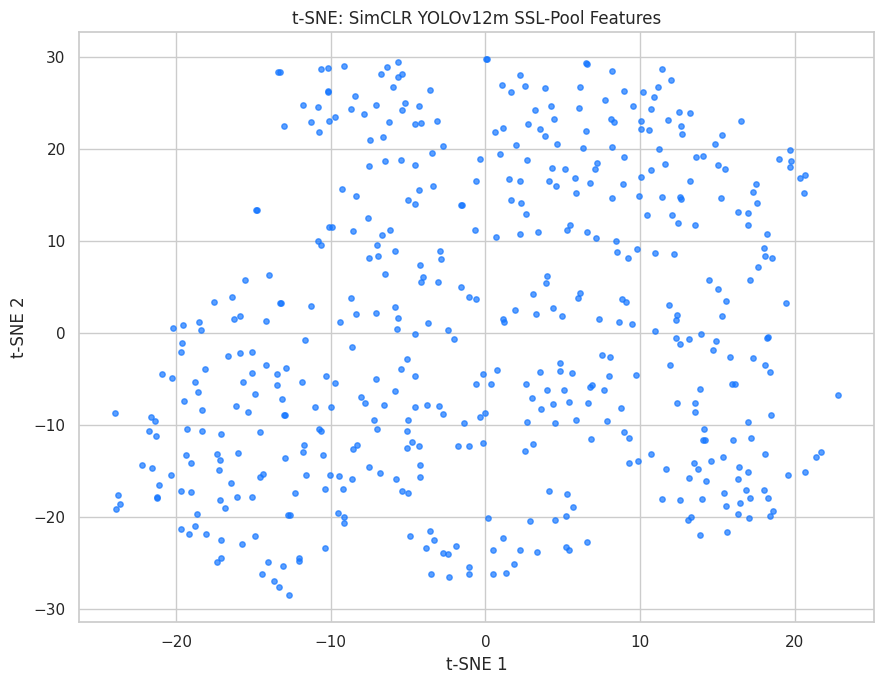

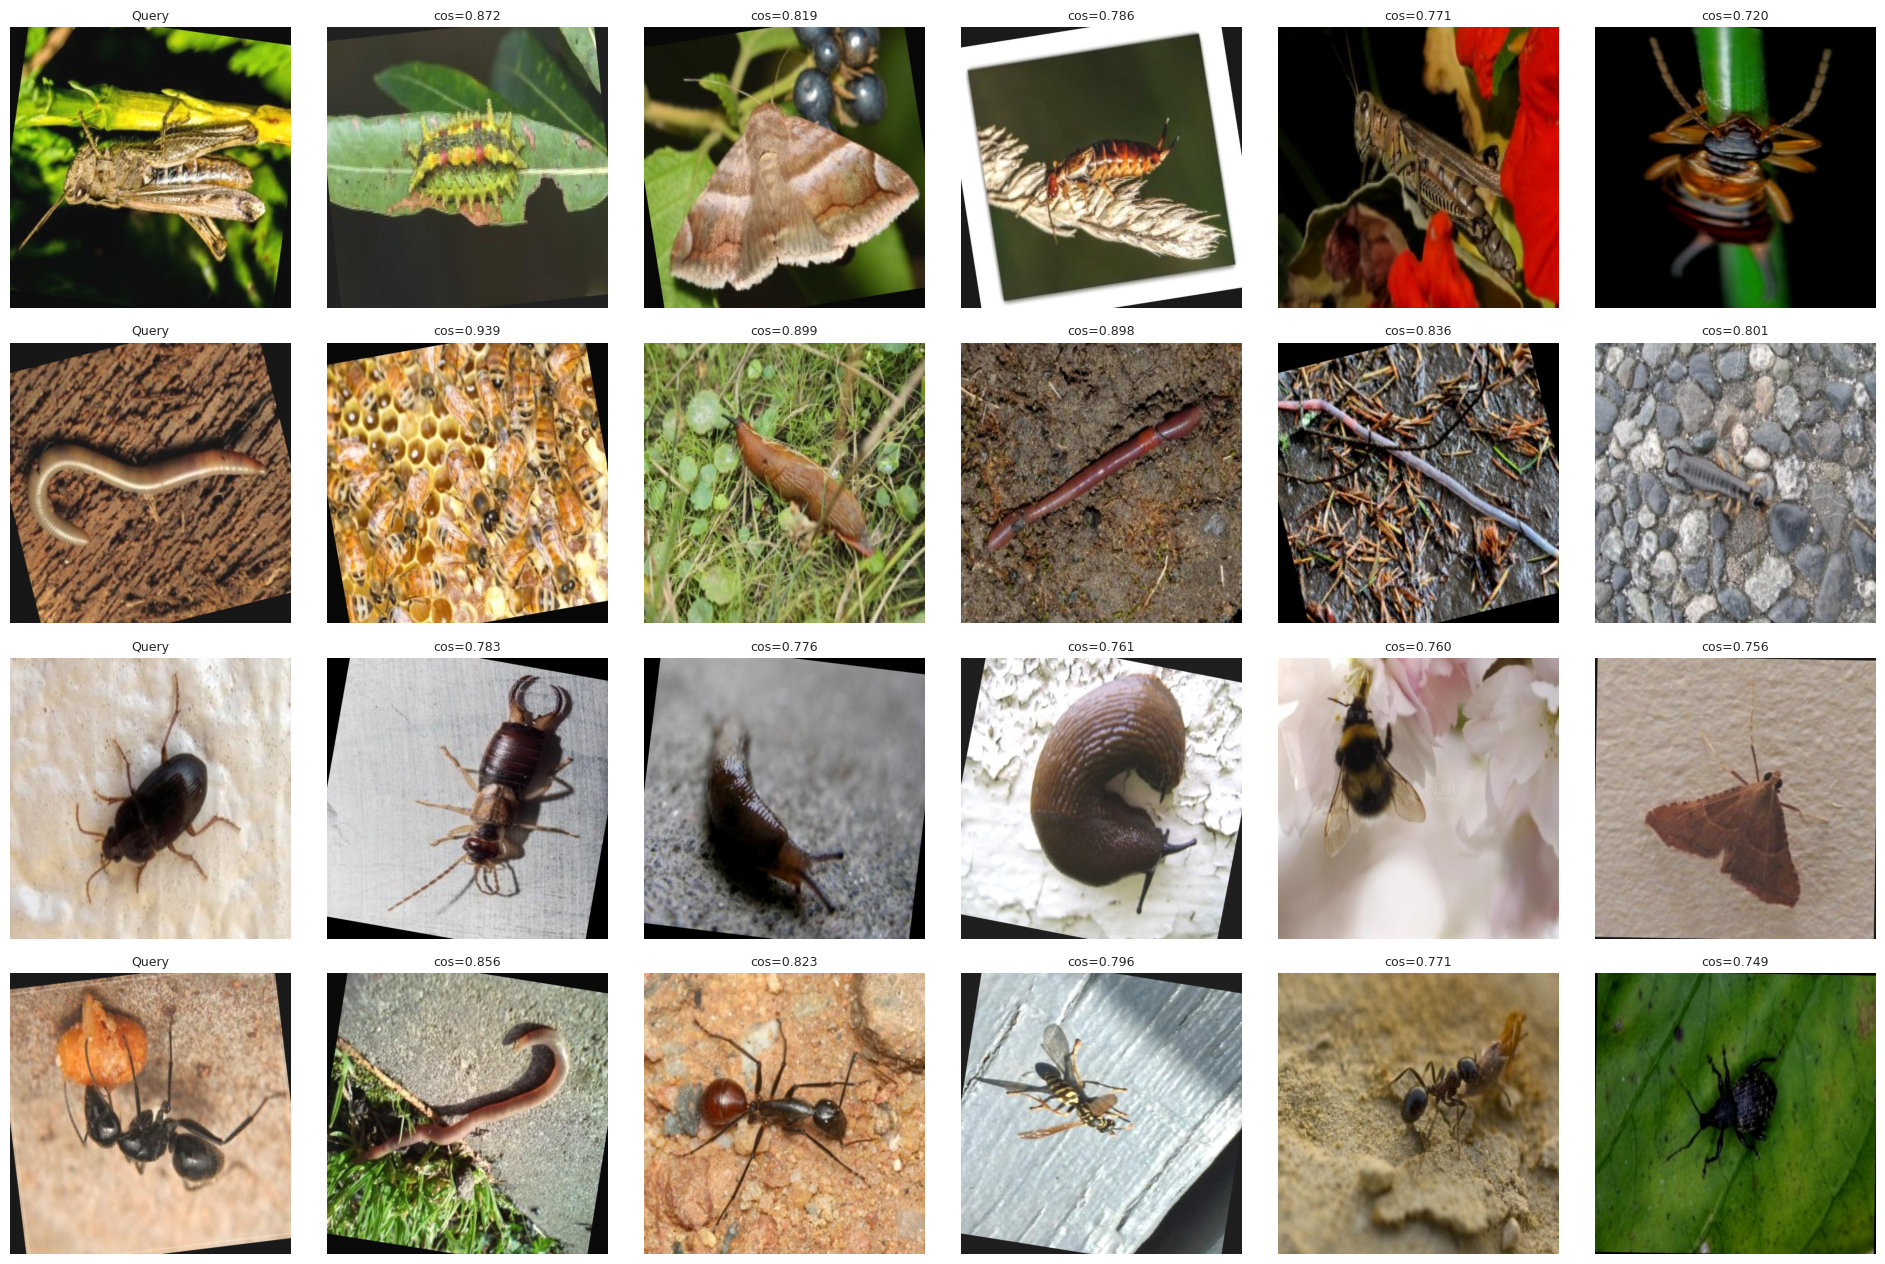

Interpretation to complete after execution: describe whether retrieved images share meaningful visual structure with the query, and defer all detection-performance claims to Notebook 01b.


In [8]:
perplexity = min(30.0, max(5.0, (len(feature_matrix) - 1) / 3))
coordinates = TSNE(n_components=2, perplexity=perplexity, learning_rate="auto", init="pca", max_iter=1000, random_state=SEED).fit_transform(feature_matrix.numpy())
fig, axis = plt.subplots(figsize=(9, 7))
axis.scatter(coordinates[:, 0], coordinates[:, 1], s=15, alpha=0.7, color="#1677ff")
axis.set(title="t-SNE: SimCLR YOLOv12m SSL-Pool Features", xlabel="t-SNE 1", ylabel="t-SNE 2")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "simclr_tsne_ssl_pool.png", dpi=160); plt.show()
pd.DataFrame({"filename": names, "tsne_1": coordinates[:, 0], "tsne_2": coordinates[:, 1]}).to_csv(OUTPUT_DIR / "ssl_pool_embeddings_tsne.csv", index=False)

query_indices = random.Random(SEED).sample(range(len(diagnostic_paths)), RETRIEVAL_QUERIES)
fig, axes = plt.subplots(RETRIEVAL_QUERIES, RETRIEVAL_NEIGHBORS + 1, figsize=(3.2 * (RETRIEVAL_NEIGHBORS + 1), 3.2 * RETRIEVAL_QUERIES))
retrieval_rows = []
for row, query_index in enumerate(query_indices):
    similarities = feature_matrix @ feature_matrix[query_index]
    neighbor_indices = [index for index in torch.topk(similarities, k=RETRIEVAL_NEIGHBORS + 1).indices.tolist() if index != query_index][:RETRIEVAL_NEIGHBORS]
    display_indices = [query_index] + neighbor_indices
    for column, index in enumerate(display_indices):
        with Image.open(diagnostic_paths[index]) as image: axes[row, column].imshow(image.convert("RGB"))
        title = "Query" if column == 0 else f"cos={similarities[index]:.3f}"
        axes[row, column].set_title(title, fontsize=9); axes[row, column].axis("off")
        retrieval_rows.append({"query": diagnostic_paths[query_index].name, "rank": column, "match": diagnostic_paths[index].name, "cosine_similarity": float(similarities[index])})
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "simclr_nearest_neighbors.png", dpi=160); plt.show()
pd.DataFrame(retrieval_rows).to_csv(OUTPUT_DIR / "simclr_nearest_neighbors.csv", index=False)

print("Interpretation to complete after execution: describe whether retrieved images share meaningful visual structure with the query, and defer all detection-performance claims to Notebook 01b.")

## Checkpoint Publication And Viva Notes

Publish the complete `/kaggle/working/partB_01a_simclr_yolo12m/` directory as a public Kaggle dataset. Notebook `01b` must attach it and use `best_ssl.pt` with its transfer report.

- SimCLR needs negatives because the other local-batch images define what the positive pair should differ from.
- Temperature scales similarities before softmax; smaller values emphasize hard negatives.
- The projection head is discarded because its contrastive space is optimized for the pretext loss; the backbone representation transfers to detection.
- Gradient accumulation does not increase simultaneous SimCLR negatives, so the per-GPU batch is selected for both T4 memory and contrastive batch diversity.